# FD001: dataset quality and exploratory analysis

**Trishit Swarnakar · Issue #3 · Phase 1**

We inspect the 100 run-to-failure training engines, document sensor selection,
and explain the team's 125-cycle training target cap. All five figures and the
CSV evidence tables below are regenerated by running this notebook top to bottom.

**Data boundary:** only `train_FD001.txt` is opened. `load_train_fd()` does not read
or require either test file. `CONTRIBUTING.md` and `ROADMAP.md` reserve test-set
analysis for issue #6; the conflicting test-plot item in issue #3 is explicitly
handed off at the end of this notebook. No models are tuned or evaluated here.

Reproduce after installing the project's pinned dependencies with `pip install -e ".[dev]"`.
Run from the repository root or `notebooks/`. Outputs are retained for review.

In [1]:
import sys
from pathlib import Path

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "rul" / "data.py").is_file() and (p / "pyproject.toml").is_file()
)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from rul.data import SENSORS, SETTINGS, USEFUL_SENSORS, add_rul, load_train_fd
from rul.eda import sensor_summary

SEED = 42
CAP = 125
FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 220})
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]

def save_figure(fig, name):
    """Write the report figure and retain an inline copy in the notebook."""
    fig.savefig(FIGURES / f"eda_{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

print({"python": sys.version.split()[0], "pandas": pd.__version__,
       "numpy": np.__version__, "matplotlib": matplotlib.__version__,
       "seaborn": sns.__version__, "seed": SEED})

{'python': '3.13.2', 'pandas': '3.1.0', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'seed': 42}


## 1. What is one observation?

Each row is one engine (`unit`) at one operating `cycle`, with three settings and
21 sensor readings. FD001 has one nominal operating condition and one fault mode
(high-pressure compressor degradation), according to the
[NASA dataset description](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data).
Engine IDs identify groups; they are not measurements of engine health.

Training engines run to failure. For unit $i$, $T_i=\max_t t$ is its final observed
cycle and the uncapped target is $r_{i,t}=T_i-t$. We calculate this **before any
filtering or smoothing**. A zero at the final cycle is therefore intentional.

In [2]:
raw_train = load_train_fd()
train = add_rul(raw_train).sort_values(["unit", "cycle"]).reset_index(drop=True)
lifetimes = train.groupby("unit")["cycle"].max().rename("lifetime_cycles")
quality = pd.Series({
    "rows": len(raw_train), "raw_columns": raw_train.shape[1],
    "engines": raw_train["unit"].nunique(),
    "missing_cells": int(raw_train.isna().sum().sum()),
    "duplicate_rows": int(raw_train.duplicated().sum()),
    "duplicate_unit_cycles": int(raw_train.duplicated(["unit", "cycle"]).sum()),
    "engines_not_starting_at_1": int((train.groupby("unit")["cycle"].min() != 1).sum()),
    "nonconsecutive_cycle_steps": int((train.groupby("unit")["cycle"].diff().dropna() != 1).sum()),
}, name="value")
assert quality["engines"] == 100 and quality["raw_columns"] == 26
assert quality[["missing_cells", "duplicate_rows", "duplicate_unit_cycles",
                "engines_not_starting_at_1", "nonconsecutive_cycle_steps"]].eq(0).all()
assert train.groupby("unit").tail(1)["rul"].eq(0).all()
quality.to_csv(RESULTS / "eda_quality.csv", index_label="check")
lifetimes.to_csv(RESULTS / "eda_lifetimes.csv")
display(quality.to_frame(), lifetimes.describe().to_frame())

,value
rows,20631
raw_columns,26
engines,100
missing_cells,0
duplicate_rows,0
duplicate_unit_cycles,0
engines_not_starting_at_1,0
nonconsecutive_cycle_steps,0


,lifetime_cycles
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


There are **20,631 training rows and 100 engines**. Recorded lifetimes range from
128 to 362 cycles (median 199, mean 206.31). No missing cells, duplicate rows, or
duplicate unit-cycle keys were found, and cycles are consecutive within each unit.
No rows are removed or imputed.

The lifetime histogram below counts each engine once. The RUL histogram counts
rows, so engines with longer histories contribute more observations. These are
different weighting schemes; neither plot is a model performance estimate.

,cap,changed_rows,changed_fraction
0,100,10531,0.510445
1,125,8031,0.389269
2,none,0,0.000000


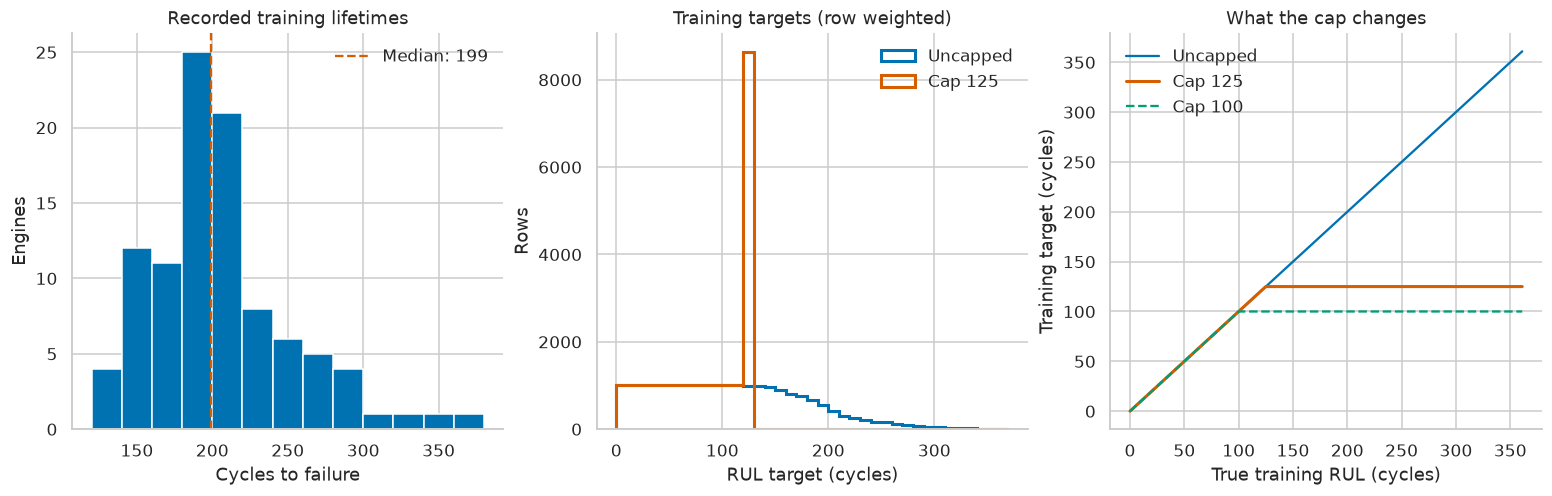

In [3]:
capped = add_rul(raw_train, cap=CAP)["rul"]
cap_comparison = pd.DataFrame([
    {"cap": str(cap), "changed_rows": int((train["rul"] > cap).sum()),
     "changed_fraction": float((train["rul"] > cap).mean())}
    for cap in [100, 125]
] + [{"cap": "none", "changed_rows": 0, "changed_fraction": 0.0}])
cap_comparison.to_csv(RESULTS / "eda_cap_comparison.csv", index=False)
display(cap_comparison)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
axes[0].hist(lifetimes, bins=np.arange(120, 381, 20), color=COLORS[0], edgecolor="white")
axes[0].axvline(lifetimes.median(), color=COLORS[1], ls="--", label="Median: 199")
axes[0].set(title="Recorded training lifetimes", xlabel="Cycles to failure", ylabel="Engines")
axes[0].legend(frameon=False)
bins = np.arange(0, 371, 10)
axes[1].hist(train["rul"], bins=bins, histtype="step", lw=2, color=COLORS[0], label="Uncapped")
axes[1].hist(capped, bins=bins, histtype="step", lw=2, color=COLORS[1], label="Cap 125")
axes[1].set(title="Training targets (row weighted)", xlabel="RUL target (cycles)", ylabel="Rows")
axes[1].legend(frameon=False)
r = np.arange(0, int(train["rul"].max()) + 1)
axes[2].plot(r, r, color=COLORS[0], label="Uncapped")
axes[2].plot(r, np.minimum(r, 125), color=COLORS[1], label="Cap 125", lw=2)
axes[2].plot(r, np.minimum(r, 100), color=COLORS[2], label="Cap 100", ls="--")
axes[2].set(title="What the cap changes", xlabel="True training RUL (cycles)", ylabel="Training target (cycles)")
axes[2].legend(frameon=False)
save_figure(fig, "lifetimes_rul")

## 2. Operating settings: one nominal condition

Small variations in settings 1 and 2 surround zero; setting 3 is exactly 100.
The scatter plots are consistent with NASA's single-condition FD001 description.
They do not prove that every possible cluster is physically meaningless. In
particular, a clustering algorithm can subdivide a single noisy cloud if asked.
We do not fit operating-regime clusters in this EDA.

,min,max,mean,std,n_unique
setting_1,-0.0087,0.0087,-0.000009,0.002187,158
setting_2,-0.0006,0.0006,0.000002,0.000293,13
setting_3,100.0000,100.0000,100.000000,0.000000,1


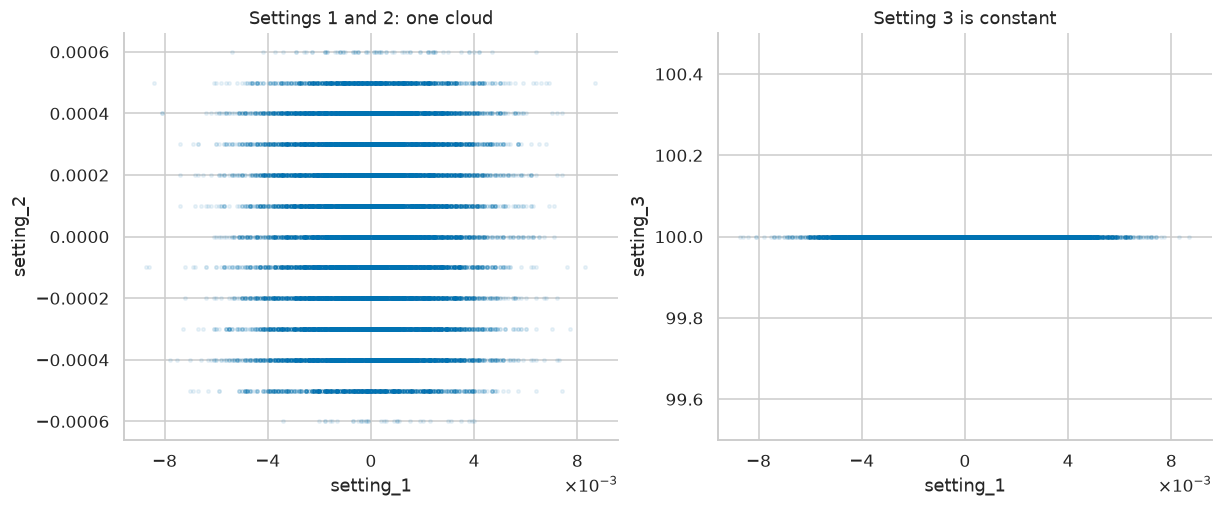

In [4]:
setting_summary = train[SETTINGS].agg(["min", "max", "mean", "std"]).T
setting_summary["n_unique"] = train[SETTINGS].nunique()
setting_summary.to_csv(RESULTS / "eda_settings.csv", index_label="setting")
display(setting_summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
axes[0].scatter(train["setting_1"], train["setting_2"], s=5, alpha=0.08,
                color=COLORS[0], rasterized=True)
axes[0].set(title="Settings 1 and 2: one cloud", xlabel="setting_1", ylabel="setting_2")
axes[1].scatter(train["setting_1"], train["setting_3"], s=5, alpha=0.08,
                color=COLORS[0], rasterized=True)
axes[1].set(title="Setting 3 is constant", xlabel="setting_1", ylabel="setting_3", ylim=(99.5, 100.5))
for ax in axes:
    ax.set_xticks(np.arange(-0.008, 0.0081, 0.004))
    ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, -3), useMathText=True)
save_figure(fig, "operating_settings")

## 3. Which sensors are flat?

We report each sensor's sample standard deviation (ddof=1), range, number of
unique readings, and dominant-value fraction. Raw standard deviations have
**different physical units**, so a single absolute variance cutoff would be misleading.

The explicit FD001 rule is:

- Drop a sensor with one unique value (exactly constant).
- Also drop a two-value sensor when at least 98% of readings equal its dominant value.
- Retain the remaining sensors; do not select them using test data or a correlation threshold.

The second criterion is an EDA choice for a nearly constant, quantized signal,
not proof that it contains zero predictive information. The threshold is documented
rather than tuned against any model score. `sensor_summary()` implements the rule.

,mean,std,min,max,n_unique,dominant_fraction,relative_std,decision
sensor,,,,,,,,
s_1,518.670000,0.000000e+00,518.6700,518.6700,1,1.000000,0.000000e+00,drop: constant
s_2,642.680934,5.000533e-01,641.2100,644.5300,310,0.009209,7.780739e-04,keep
s_3,1590.523119,6.131150e+00,1571.0400,1616.9100,3012,0.001309,3.854801e-03,keep
s_4,1408.933782,9.000605e+00,1382.2500,1441.4900,4051,0.000969,6.388238e-03,keep
s_5,14.620000,5.329200e-15,14.6200,14.6200,1,1.000000,3.645143e-16,drop: constant
s_6,21.609803,1.388985e-03,21.6000,21.6100,2,0.980321,6.427569e-05,drop: near-constant binary
s_7,553.367711,8.850923e-01,549.8500,556.0600,513,0.005623,1.599465e-03,keep
s_8,2388.096652,7.098548e-02,2387.9000,2388.5600,53,0.057244,2.972471e-05,keep
s_9,9065.242941,2.208288e+01,9021.7300,9244.5900,6403,0.000776,2.435994e-03,keep


Kept: ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
Dropped: ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']
s_6 value counts: {21.61: 20225, 21.6: 406}


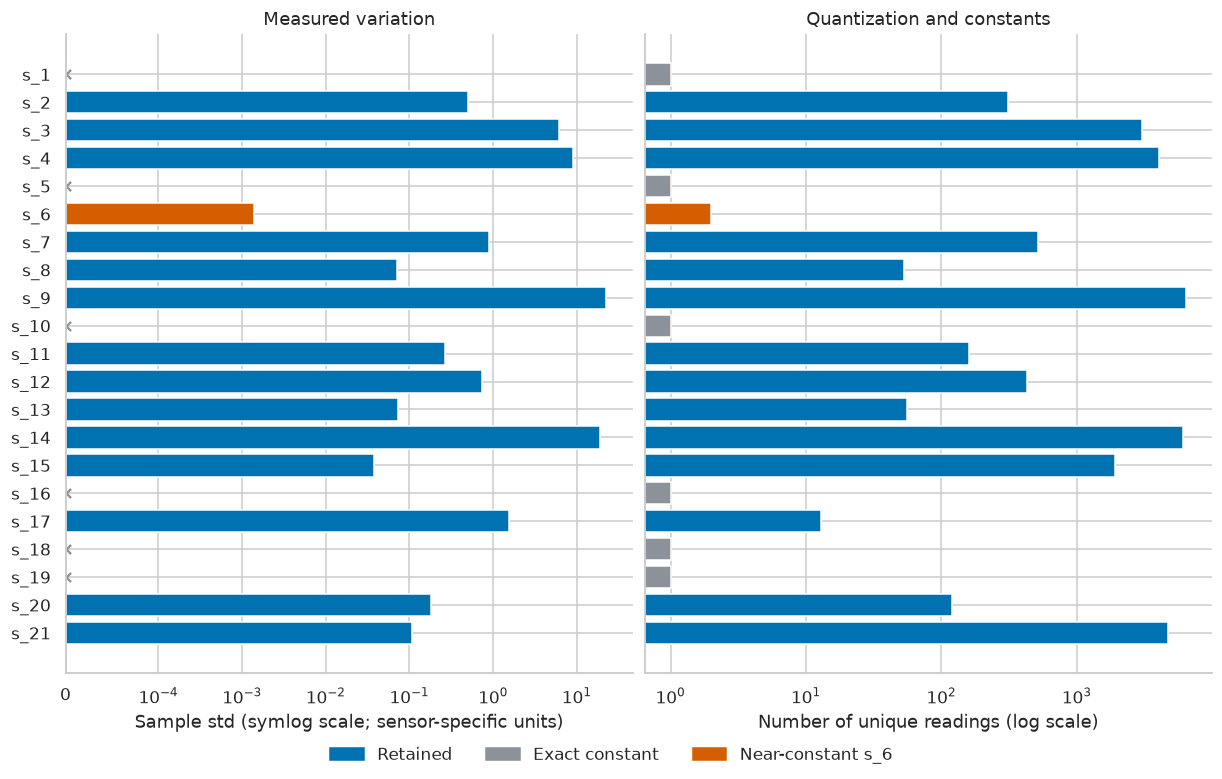

In [5]:
summary = sensor_summary(train, SENSORS)
summary.to_csv(RESULTS / "eda_sensor_summary.csv")
kept = summary.index[summary["decision"] == "keep"].tolist()
dropped = summary.index[summary["decision"] != "keep"].tolist()
assert kept == USEFUL_SENSORS, "Exported sensor list and EDA evidence have drifted"
display(summary)
print("Kept:", kept)
print("Dropped:", dropped)
print("s_6 value counts:", train["s_6"].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True, layout="constrained")
y = np.arange(len(SENSORS))
colors = [COLORS[0] if s in kept else (COLORS[1] if s == "s_6" else "#8B9299") for s in SENSORS]
# Exact constants are zero; floating-point std roundoff is not real variation.
std_plot = summary["std"].where(summary["n_unique"] > 1, 0)
axes[0].barh(y, std_plot, color=colors)
axes[0].scatter(np.zeros(sum(summary["n_unique"] == 1)),
                y[summary["n_unique"].to_numpy() == 1], color="#8B9299", marker="x")
axes[0].set_xscale("symlog", linthresh=0.0001)
axes[0].set(yticks=y, yticklabels=SENSORS, xlabel="Sample std (symlog scale; sensor-specific units)",
            title="Measured variation")
axes[0].invert_yaxis()
axes[1].barh(y, summary["n_unique"], color=colors)
axes[1].set_xscale("log")
axes[1].set(xlabel="Number of unique readings (log scale)", title="Quantization and constants")
from matplotlib.patches import Patch

fig.legend(handles=[Patch(color=COLORS[0], label="Retained"),
                    Patch(color="#8B9299", label="Exact constant"),
                    Patch(color=COLORS[1], label="Near-constant s_6")],
           loc="outside lower center", ncol=3, frameon=False)
save_figure(fig, "sensor_variation")

The six exact constants are **s_1, s_5, s_10, s_16, s_18, s_19**. Some computed
standard deviations are tiny nonzero numbers because of floating-point arithmetic;
one unique value is the decisive evidence.

**s_6** has std approximately 0.001389 and only two readings: 21.61 occurs 20,225
times, and 21.60 occurs 406 times. Its dominant fraction is **98.03%**. This is why
we also drop s_6, rather than relying on the issue's approximate list alone.

The 14 retained sensors are exported as `USEFUL_SENSORS` in `src/rul/data.py`.
Sensor s_17 is retained despite being quantized: it has 13 distinct values and is
not nearly constant. Sensor choice is specific to FD001; it should be revisited
for other operating conditions or datasets.

## 4. Sensor trends aligned to failure

Five engines are sampled without replacement using seed 42: **9, 44, 65, 76, 100**.
The x-axis runs from high RUL on the left to failure (RUL=0) on the right. Each
panel shows a representative retained sensor. Faint lines show raw readings;
solid lines are **11-cycle trailing means computed separately within each engine**,
with shorter windows at the start. This smoothing is for visualization only.
The dashed line marks RUL=125; the shaded region contains uncapped RUL above 125.

Sample engines: [9, 44, 65, 76, 100]


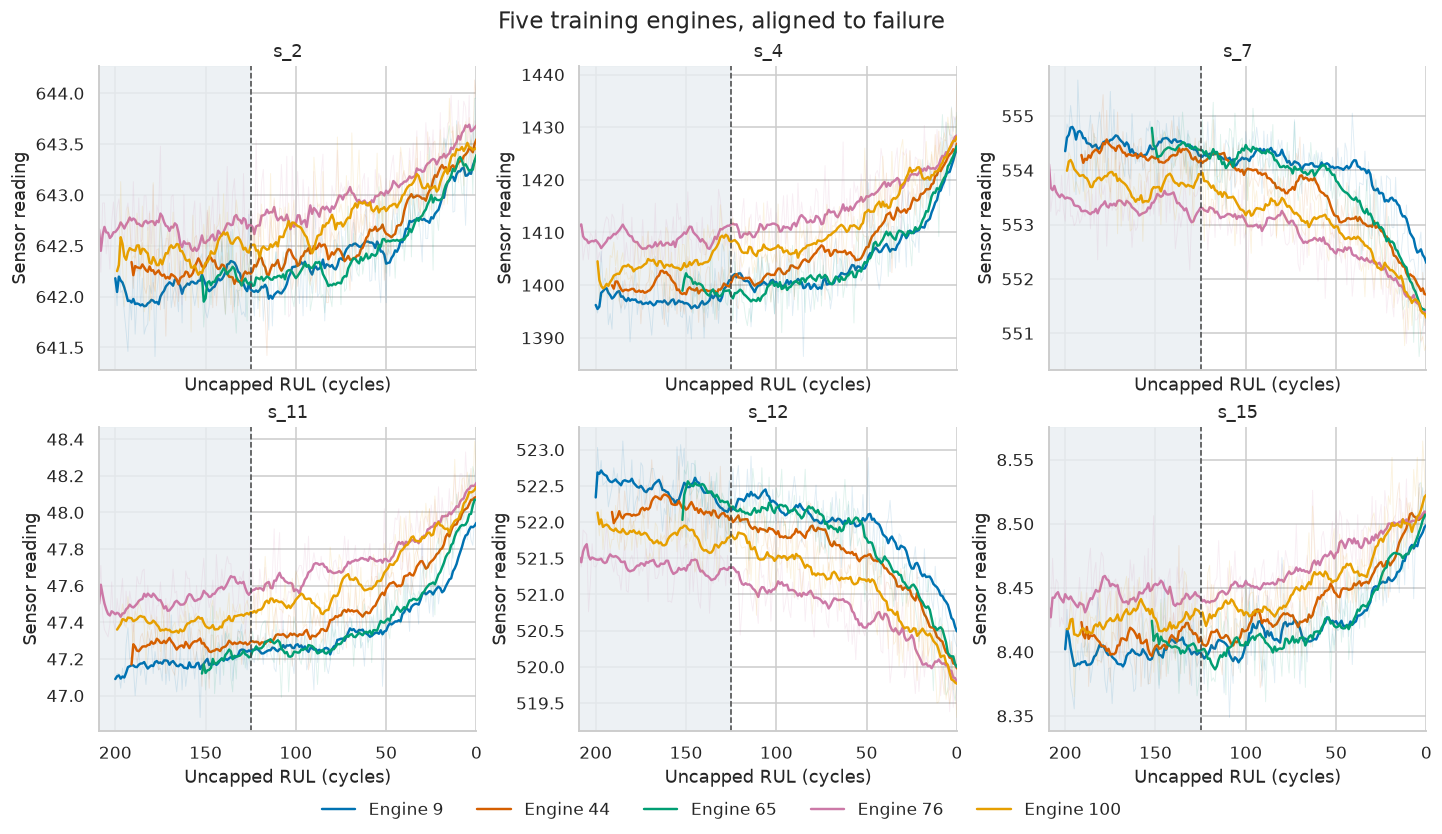

In [6]:
sample_units = sorted(np.random.default_rng(SEED).choice(train["unit"].unique(), 5, replace=False).tolist())
trend_sensors = ["s_2", "s_4", "s_7", "s_11", "s_12", "s_15"]
print("Sample engines:", sample_units)
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, layout="constrained")
max_rul = int(train.loc[train["unit"].isin(sample_units), "rul"].max())
for ax, sensor in zip(axes.flat, trend_sensors):
    ax.axvspan(CAP, max_rul, color="#E9EEF2", alpha=0.8)
    for unit, color in zip(sample_units, COLORS):
        engine = train.loc[train["unit"] == unit].sort_values("cycle")
        smooth = engine[sensor].rolling(11, min_periods=1).mean()
        ax.plot(engine["rul"], engine[sensor], color=color, alpha=0.12, lw=0.6)
        ax.plot(engine["rul"], smooth, color=color, lw=1.6, label=f"Engine {unit}")
    ax.axvline(CAP, color="#444444", ls="--", lw=1)
    ax.set(title=sensor, xlabel="Uncapped RUL (cycles)", ylabel="Sensor reading", xlim=(max_rul, 0))
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5, frameon=False)
fig.suptitle("Five training engines, aligned to failure", fontsize=15)
save_figure(fig, "sensor_trends")

The selected sensors show clearer directional changes nearer failure: s_2, s_4,
s_11 and s_15 generally rise, while s_7 and s_12 fall. Early portions are often
flatter and engine baselines differ. The curves are noisy and not identical,
so this figure supports a modeling assumption rather than a universal failure-onset rule.

### Why a 125-cycle cap?

We use $y_{i,t}=\min(125,T_i-t)$ for training, as specified in `ROADMAP.md`.
Liu, Wang and Yu (2021), Section 4.2, explicitly use a piecewise target with an
upper limit of 125 for C-MAPSS ([paper and DOI](https://doi.org/10.1007/s44196-021-00020-1)).
Their motivation is weak degradation information early in operation. Our plots
are consistent with that motivation; they do **not** establish that early RUL is
impossible to learn or that 125 is the best threshold.

Here, 8,031 of 20,631 training rows (38.93%) have true RUL above 125 and are changed
by this cap. A cap of 100 creates a longer plateau and loses more early-life target
resolution. No cap preserves exact targets but asks the model to distinguish more
early-life states with similar sensor readings. Issue #5 compares the chosen cap
with an uncapped run using engine-grouped cross-validation. True final test labels
remain uncapped for evaluation.

## 5. Correlation of retained sensors with RUL

This is a Pearson correlation matrix using **uncapped** training RUL. Constants
are removed before calculation because their correlations are undefined. No sensor
is dropped simply because it correlates with another sensor. Multicollinearity
and model-specific usefulness are questions for feature/model evaluation.

,pearson_r_with_uncapped_rul
s_11,-0.696228
s_4,-0.678948
s_15,-0.642667
s_2,-0.606484
s_17,-0.606154
s_3,-0.584520
s_8,-0.563968
s_13,-0.562569
s_9,-0.390102
s_14,-0.306769


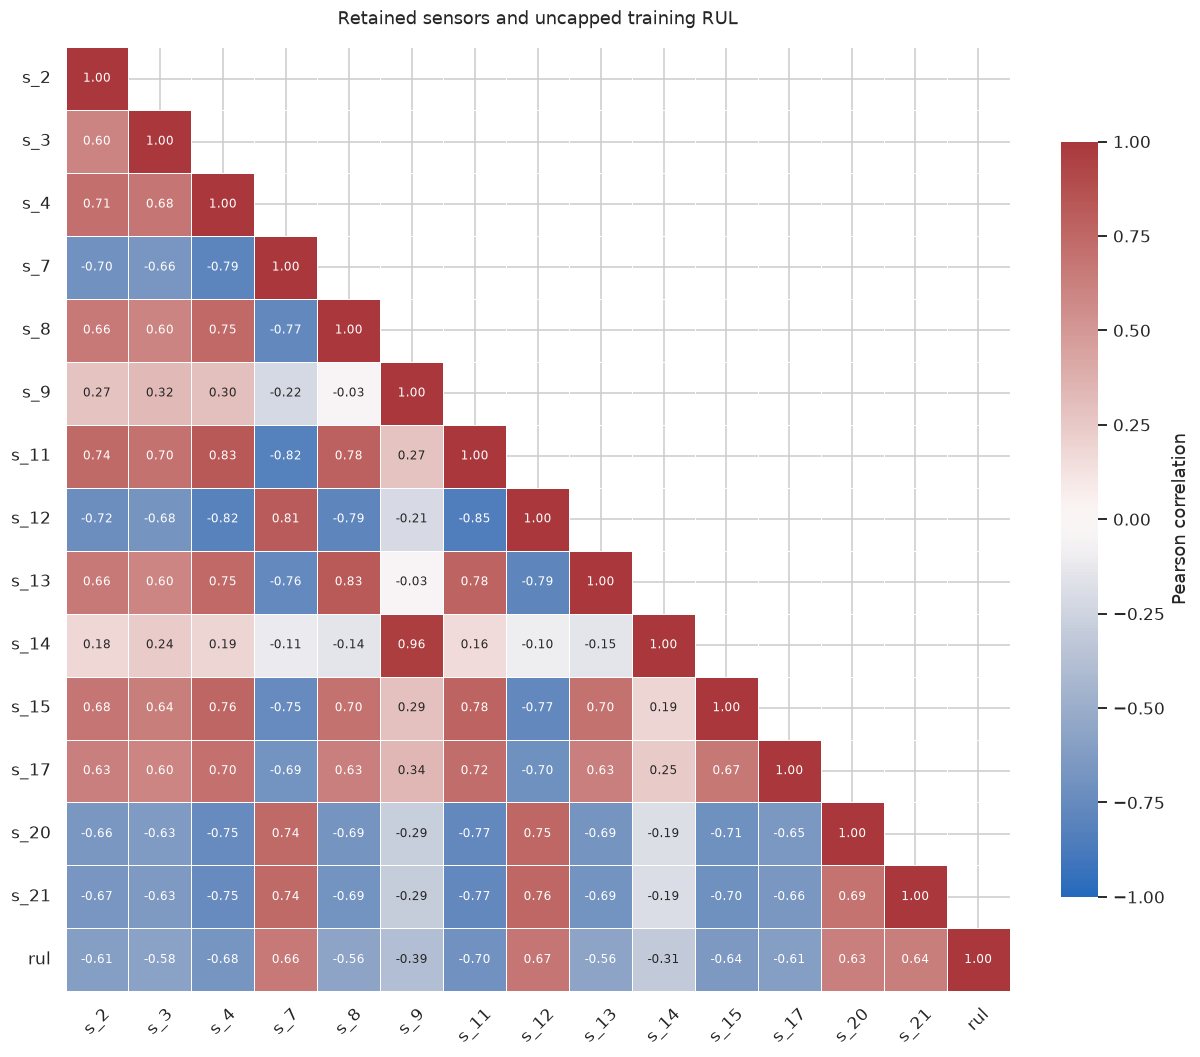

In [7]:
correlation = train[kept + ["rul"]].corr(method="pearson")
correlation.to_csv(RESULTS / "eda_correlations.csv")
display(correlation["rul"].drop("rul").sort_values().to_frame("pearson_r_with_uncapped_rul"))
fig, ax = plt.subplots(figsize=(11, 9.5), layout="constrained")
mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)
sns.heatmap(correlation, mask=mask, vmin=-1, vmax=1, center=0, cmap="vlag",
            annot=True, fmt=".2f", annot_kws={"fontsize": 8}, square=True,
            linewidths=0.4, cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Retained sensors and uncapped training RUL", pad=15)
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
save_figure(fig, "correlations")

The heatmap shows substantial shared variation among several retained sensors and
associations with remaining life. These are **pooled, row-weighted descriptive
correlations**: neighboring cycles are dependent, and between-engine differences
can contribute. They are neither causal effects nor independent-sample significance tests.
A weak linear correlation also does not rule out useful nonlinear or temporal information.

Any scaler or learned feature transformation used for model evaluation must be fit
inside each training fold. The plots and statistics here are descriptive and are
not a fitted preprocessing pipeline to reuse across validation folds.

## 6. Test diagnostics handed off to issue #6

Issue #3 asks for test-truncation and true-test-RUL distributions, but both
`CONTRIBUTING.md` and `ROADMAP.md` reserve the test set for final evaluation after
hyperparameters are frozen. **Those two plots are deferred, not silently marked done.**
No test observations or labels were opened by this notebook.

At final evaluation, plot the distribution of true test RUL and the observed
fraction $t_{last}/(t_{last}+r_{test})$ for each unit. This fraction describes the
recorded trajectory horizon, not an engine's entire physical life: initial wear
is unknown. These diagnostics must not feed back into sensor choice, target-cap
selection, or hyperparameter tuning.

## References and handoff

- Saxena, A., Goebel, K., Simon, D., and Eklund, N. (2008). *Damage Propagation
  Modeling for Aircraft Engine Run-to-Failure Simulation*. PHM 2008.
  [NASA dataset](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data).
- Liu, L., Wang, L., and Yu, Z. (2021). *Remaining Useful Life Estimation of Aircraft
  Engines Based on Deep Convolution Neural Network and LightGBM Combination Model*.
  International Journal of Computational Intelligence Systems, 14, 165.
  [doi:10.1007/s44196-021-00020-1](https://doi.org/10.1007/s44196-021-00020-1), Section 4.2.

Feature and model owners can import `USEFUL_SENSORS`. Source values for the report
are in `results/eda_*.csv`; the five figures are in `figures/eda_*.png`. The dataset
and EDA report section is `report/sections/data.tex`; explanations and practice
questions are in `docs/viva/trishit.md`.